# 03. 감정 → 행성 외형 매핑 설계 (초안 v0.1)

**목적**: 감정 분류 모델이 출력한 44개 감정 확률을 **행성 외형 파라미터**(색, 띠, 빛, 고리, 크기)로 바꾸는 규칙을 설계하고,
실제 모델 출력에 적용했을 때 행성이 지나치게 한쪽으로 쏠리거나 모두 비슷해지지 않는지 점검한다.

- 규칙과 수치: `ai/configs/planet_mapping.json` · 계산: `ai/src/emotion/planet_mapping.py` · 미리보기: `ai/src/emotion/planet_preview.py`
- 3D 렌더링은 프론트 담당이다. 여기서는 파라미터와 2D 미리보기까지만 만든다.
- 색·수치는 **설계 초안**이다. 기획·프론트 협의와 사용자 검토로 조정해야 한다.

| 행성 속성 | 결정 규칙 |
|---|---|
| 기본색 | 점수가 가장 높은 감정 그룹의 색 (그룹 점수 = 그룹 안 라벨 확률의 최댓값) |
| 보조색·띠 | 두 번째 그룹 색. 섞임 비율 = 두 그룹 점수 비. 띠 개수는 각성(arousal)이 높을수록 많음 |
| 채도 | ‘없음’ 확률이 높을수록 낮아짐 (담담한 일기 → 옅은 행성) |
| 빛 번짐 | 쾌(valence)가 높고 감정이 강할수록 밝음 |
| 표면 소용돌이 | 각성이 높을수록 거침 |
| 고리 | 활성 그룹(점수 ≥ `active_min`)이 3개 이상이면 ‘복합 감정’ 고리 |
| 크기 | 가장 강한 그룹 점수에 비례 (0.85 ~ 1.15배) |

## 1. 환경과 설정

In [1]:
import os
import sys
import json
import platform
from pathlib import Path


def find_ai_root(start: Path) -> Path:
    """현재 위치에서 위로 올라가며 ai/ 폴더를 찾는다(저장소 루트·ai/·ai/notebooks/ 모두 지원)."""
    for p in [start, *start.parents]:
        if p.name == "ai" and (p / "src" / "data" / "paths.py").is_file():
            return p
        if (p / "ai" / "src" / "data" / "paths.py").is_file():
            return p / "ai"
    raise FileNotFoundError("ai/ 폴더를 찾지 못했습니다. 저장소 안에서 실행하세요.")


AI_ROOT = find_ai_root(Path.cwd().resolve())
if str(AI_ROOT) not in sys.path:
    sys.path.insert(0, str(AI_ROOT))

# 커널 점검: 저장소 .venv(학습 패키지 포함)가 아니면 여기서 멈추고 안내한다.
from src.env_check import assert_environment
ENV = assert_environment(AI_ROOT / "requirements-train.txt", AI_ROOT.parent)

from src.data.paths import get_paths, configure_hf_cache, load_json

P = get_paths(AI_ROOT)
configure_hf_cache(P)                       # transformers import 전에 호출
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"


def rel(p) -> str:
    return Path(p).resolve().relative_to(P.repo_root).as_posix()

Python 3.13.5 | 저장소 .venv 커널 사용: 예
  numpy            필요 2.5.3      설치 2.5.3            OK
  pandas           필요 3.0.6      설치 3.0.6            OK
  pyarrow          필요 25.0.1     설치 25.0.1           OK
  matplotlib       필요 3.11.2     설치 3.11.2           OK
  huggingface_hub  필요 1.33.0     설치 1.33.0           OK
  transformers     필요 5.19.0     설치 5.19.0           OK
  ipykernel        필요 7.4.0      설치 7.4.0            OK
  torch            필요 2.14.1+cu130 설치 2.14.1+cu130     OK


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

warnings.filterwarnings("ignore", message="IProgress not found")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
ANALYSIS_CFG = load_json(P.configs / "analysis.json")
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
KOREAN_FONT = next((f for f in ANALYSIS_CFG["figure"]["korean_font_candidates"] if f in installed_fonts), None)
if KOREAN_FONT:
    plt.rcParams["font.family"] = KOREAN_FONT
else:
    print("경고: 한글 글꼴을 찾지 못했습니다.")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["figure.dpi"] = ANALYSIS_CFG["figure"]["dpi"]
for side in ("top", "right"):
    plt.rcParams[f"axes.spines.{side}"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]


def show_fmt(df: pd.DataFrame, formats: dict, index: bool = True):
    """열별 표시 형식만 바꿔 보여준다(원본 DataFrame은 그대로)."""
    d = df.copy()
    for c, f in formats.items():
        d[c] = d[c].map(lambda v, f=f: f.format(v) if pd.notna(v) else "")
    display(d if index else d.reset_index(drop=True))


def save_fig(fig, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        fig.savefig(path, bbox_inches="tight", facecolor=fig.get_facecolor())
    missing = [x for x in w if "missing from font" in str(x.message)]
    print(f"그림 저장: {rel(path)}" + (f" | 글꼴 누락 경고 {len(missing)}건" if missing else " | 글꼴 누락 없음"))

from collections import Counter
from itertools import combinations
from src.data.labels import load_label_names
from src.emotion.planet_mapping import load_mapping, validate_mapping, compute_planet, group_scores
from src.emotion.planet_preview import render_planet, SPACE_BG

LABELS = load_label_names(P.configs / "kote_labels.json")
MAPPING = load_mapping(P.configs / "planet_mapping.json")
validate_mapping(MAPPING, LABELS)
print("매핑 검증: 44개 라벨이 10개 그룹 + ‘없음’에 정확히 한 번씩 배정됨 | 버전", MAPPING["version"])

EMO_OUT = P.ai_root / "outputs" / "emotion"
runs = sorted([p for p in EMO_OUT.iterdir() if p.is_dir() and not p.name.startswith("smoke_")
               and (p / "metrics.json").exists()], key=lambda p: p.stat().st_mtime)
RUN_ID = "baseline_v2021_s42"   # 매핑 파라미터(active_min)를 보정한 감정 모델. 모델을 바꾸면 4절로 다시 보정한다.
RUN = EMO_OUT / RUN_ID if RUN_ID else runs[-1]
FIG = RUN / "figures"
print("감정 모델 결과:", rel(RUN))

매핑 검증: 44개 라벨이 10개 그룹 + ‘없음’에 정확히 한 번씩 배정됨 | 버전 0.1-draft
감정 모델 결과: ai/outputs/emotion/baseline_v2021_s42


## 2. 감정 그룹 설계

그룹별 색과 정서 좌표(valence: 불쾌 -1 ~ 쾌 +1, arousal: 차분 0 ~ 각성 1). 정서 좌표는 Russell(1980) 정서 원형 모델을 틀로 삼아 설계자가 정한 값이다.

,그룹,id,색,valence,arousal,라벨 수,라벨
0,기쁨·즐거움,joy,#FFD23F,0.9,0.70,5,"즐거움/신남, 기쁨, 행복, 흐뭇함(귀여움/예쁨), 뿌듯함"
1,감사·애정,warmth,#FF8FB1,0.8,0.45,5,"고마움, 아껴주는, 환영/호의, 존경, 감동/감탄"
2,평온·안심,calm,#5ED3A4,0.6,0.15,2,"편안/쾌적, 안심/신뢰"
3,기대·호기심,curiosity,#3EC6E0,0.4,0.60,5,"기대감, 신기함/관심, 놀람, 깨달음, 비장함"
4,분노·불만,anger,#E5383B,-0.8,0.85,5,"화남/분노, 짜증, 불평/불만, 지긋지긋, 어이없음"
5,혐오·불신,contempt,#7A8B2E,-0.7,0.50,5,"증오/혐오, 역겨움/징그러움, 한심함, 우쭐댐/무시함, 의심/불신"
6,슬픔·상실,sadness,#3A5BD9,-0.8,0.25,5,"슬픔, 서러움, 절망, 불쌍함/연민, 안타까움/실망"
7,불안·당황,anxiety,#8E5BD9,-0.6,0.75,4,"불안/걱정, 공포/무서움, 당황/난처, 경악"
8,지침·무기력,fatigue,#8C7B6B,-0.5,0.10,4,"힘듦/지침, 귀찮음, 부담/안_내킴, 재미없음"
9,부끄러움·자책,shame,#A23B72,-0.7,0.40,3,"부끄러움, 죄책감, 패배/자기혐오"


그림 저장: ai/outputs/emotion/baseline_v2021_s42/figures/planet_groups.png | 글꼴 누락 없음


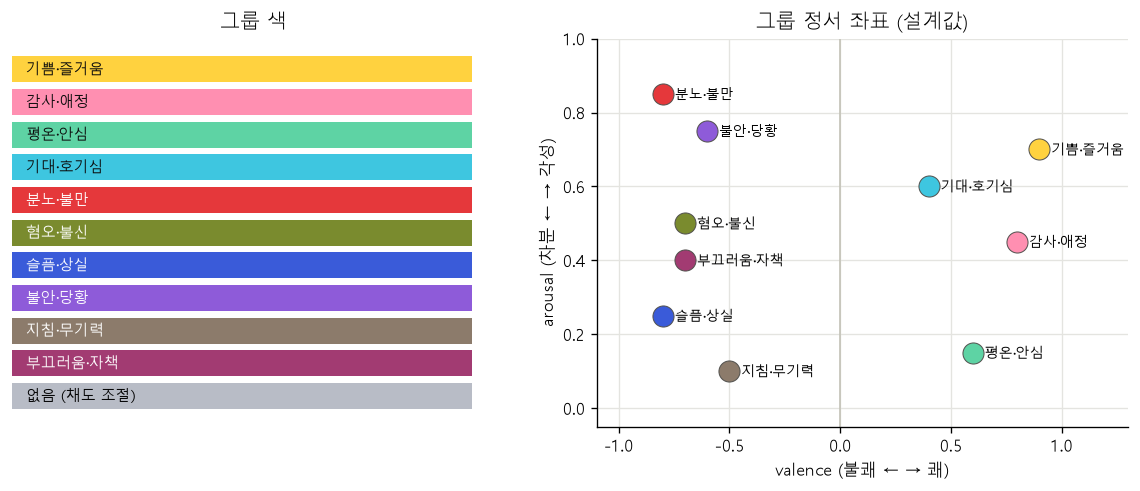

In [3]:
gt = pd.DataFrame([{"그룹": g["name"], "id": g["id"], "색": g["color"], "valence": g["valence"],
                    "arousal": g["arousal"], "라벨 수": len(g["labels"]), "라벨": ", ".join(g["labels"])}
                   for g in MAPPING["groups"]])
pd.set_option("display.max_colwidth", 90)
display(gt)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
for i, g in enumerate(MAPPING["groups"]):
    ax.barh(i, 1, color=g["color"], height=0.8)
    ax.text(0.03, i, g["name"], va="center", fontsize=9,
            color="white" if g["id"] in ("sadness", "anxiety", "shame", "anger", "contempt", "fatigue") else "#0b0b0b")
ax.barh(len(MAPPING["groups"]), 1, color=MAPPING["neutral"]["color"], height=0.8)
ax.text(0.03, len(MAPPING["groups"]), "없음 (채도 조절)", va="center", fontsize=9)
ax.invert_yaxis()
ax.axis("off")
ax.set_title("그룹 색")
ax = axes[1]
for g in MAPPING["groups"]:
    ax.scatter(g["valence"], g["arousal"], s=160, color=g["color"], edgecolor="#52514e", linewidth=0.6, zorder=3)
    ax.annotate(g["name"], (g["valence"], g["arousal"]), xytext=(7, -3), textcoords="offset points", fontsize=8.5)
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set_xlim(-1.1, 1.3)
ax.set_ylim(-0.05, 1.0)
ax.set_xlabel("valence (불쾌 ← → 쾌)")
ax.set_ylabel("arousal (차분 ← → 각성)")
ax.set_title("그룹 정서 좌표 (설계값)")
ax.grid(color="#e4e4e0", lw=0.8)
save_fig(fig, FIG / "planet_groups.png")
plt.show()

## 3. 설계 그룹과 데이터 군집 비교

**목적**: 그룹을 임의로 정하지 않았는지 확인한다. KOTE train의 감정 공존 Jaccard 거리(1 − Jaccard)로 평균연결 계층 군집을 만들고,
큰 덩어리(3개 이상 라벨)와 설계 그룹이 얼마나 겹치는지 본다. 설계 그룹의 라벨이 모두 같은 데이터 덩어리에 있으면 ‘일치’로 본다.

In [4]:
C = pd.read_csv(P.outputs_kote / "cooccurrence_matrix_train.csv", index_col=0, encoding="utf-8-sig")
assert list(C.index) == LABELS
C = C.values.astype(float)
n = np.diag(C)
D = 1 - C / (n[:, None] + n[None, :] - C)
np.fill_diagonal(D, 0)


def average_linkage(D: np.ndarray, k: int) -> list[list[int]]:
    clusters = [[i] for i in range(len(D))]
    while len(clusters) > k:
        best = None
        for a, b in combinations(range(len(clusters)), 2):
            d = D[np.ix_(clusters[a], clusters[b])].mean()
            if best is None or d < best[0]:
                best = (d, a, b)
        _, a, b = best
        clusters[a] += clusters.pop(b)
    return clusters


K = 10
data_clusters = sorted(average_linkage(D, K), key=lambda c: -len(c))
block_of = {}
for ci, c in enumerate(data_clusters):
    name = f"덩어리{ci + 1}" if len(c) >= 3 else "단독/소군집"
    for i in c:
        block_of[LABELS[i]] = name
for ci, c in enumerate(data_clusters):
    if len(c) >= 3:
        print(f"덩어리{ci + 1} ({len(c)}개):", ", ".join(LABELS[i] for i in c))
print("단독/소군집:", ", ".join(LABELS[i] for c in data_clusters if len(c) < 3 for i in c))

rows = []
for g in MAPPING["groups"]:
    blocks = Counter(block_of[l] for l in g["labels"])
    main, cnt = blocks.most_common(1)[0]
    rows.append({"설계 그룹": g["name"], "주 데이터 덩어리": main, "일치 라벨": f"{cnt}/{len(g['labels'])}",
                 "다른 덩어리 라벨": ", ".join(f"{l}({block_of[l]})" for l in g["labels"] if block_of[l] != main)})
display(pd.DataFrame(rows))

덩어리1 (16개): 환영/호의, 기대감, 신기함/관심, 감동/감탄, 즐거움/신남, 행복, 기쁨, 고마움, 안심/신뢰, 뿌듯함, 아껴주는, 흐뭇함(귀여움/예쁨), 편안/쾌적, 존경, 깨달음, 놀람
덩어리2 (13개): 불평/불만, 짜증, 화남/분노, 한심함, 어이없음, 안타까움/실망, 의심/불신, 당황/난처, 지긋지긋, 역겨움/징그러움, 증오/혐오, 경악, 우쭐댐/무시함
덩어리3 (7개): 슬픔, 절망, 서러움, 힘듦/지침, 불쌍함/연민, 불안/걱정, 패배/자기혐오
단독/소군집: 귀찮음, 부담/안_내킴, 비장함, 부끄러움, 공포/무서움, 없음, 죄책감, 재미없음


,설계 그룹,주 데이터 덩어리,일치 라벨,다른 덩어리 라벨
0,기쁨·즐거움,덩어리1,5/5,
1,감사·애정,덩어리1,5/5,
2,평온·안심,덩어리1,2/2,
3,기대·호기심,덩어리1,4/5,비장함(단독/소군집)
4,분노·불만,덩어리2,5/5,
5,혐오·불신,덩어리2,5/5,
6,슬픔·상실,덩어리3,4/5,안타까움/실망(덩어리2)
7,불안·당황,덩어리2,2/4,"불안/걱정(덩어리3), 공포/무서움(단독/소군집)"
8,지침·무기력,단독/소군집,3/4,힘듦/지침(덩어리3)
9,부끄러움·자책,단독/소군집,2/3,패배/자기혐오(덩어리3)


**결과 해석**

- 데이터 군집(k=10)의 큰 덩어리는 긍정(16개), 비판·분노(13개), 슬픔(7개) 세 개이고, 희소 라벨 8개는 단독으로 떨어진다.
- 설계 그룹 10개 중 5개(기쁨·즐거움, 감사·애정, 평온·안심, 분노·불만, 혐오·불신)는 라벨 전부가 같은 데이터 덩어리 안에 있다. 즉 큰 덩어리를 **의미 기준으로 쪼갠 것**이고, 덩어리를 가로질러 섞지 않았다.
- 덩어리와 다르게 배정한 라벨은 6개다: 비장함, 안타까움/실망, 불안/걱정, 공포/무서움, 힘듦/지침, 패배/자기혐오. 각각의 근거는 `planet_mapping.json`의 `group_notes`에 적었다.
- 가장 큰 설계 판단은 **안타까움/실망을 슬픔 쪽으로 옮긴 것**이다. 데이터에서는 불평/불만과 자주 함께 나오지만(댓글 특성), 일기에서는 아쉬움에 가깝다고 보았다. 미팅에서 확인받을 사항이다.

## 4. 고리 기준 보정 (validation)

**목적**: 고리는 ‘복합 감정’ 표시이므로 너무 흔하거나 너무 드물면 의미가 없다. KOTE 원시 주석에서
**평가자 3명 이상이 고른 감정 그룹이 3개 이상인 댓글**을 ‘뚜렷한 복합 감정’으로 정의하고,
validation에서 고리 비율이 이 기준에 가장 가까운 `active_min`을 고른다(test는 확인용으로만 사용).

In [5]:
from src.data.kote_load import load_raw_annotations
from src.data.labels import rater_vote_counts

raw = load_raw_annotations(P.raw_kote)
name_to_id = {n: i for i, n in enumerate(LABELS)}
gidx = [[LABELS.index(l) for l in g["labels"]] for g in MAPPING["groups"]]


def group_votes(split):
    ids = pd.read_csv(RUN / f"{split}_ids.csv", dtype=str)["ID"].tolist()
    V = np.stack([rater_vote_counts(raw[i]["labels"], name_to_id, len(LABELS)) for i in ids])
    return np.stack([V[:, ix].max(1) for ix in gidx], 1)


Vg_val = group_votes("validation")
val_probs = np.load(RUN / "validation_probs.npy")
S_val = np.stack([val_probs[:, ix].max(1) for ix in gidx], 1)
ref_val = ((Vg_val >= 3).sum(1) >= 3).mean()
k_ring = MAPPING["params"]["ring_min_active_groups"]
rows = [{"active_min": a, "고리 비율": ((S_val >= a).sum(1) >= k_ring).mean(), "활성 그룹 수 평균": (S_val >= a).sum(1).mean()}
        for a in (0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9)]
cal = pd.DataFrame(rows)
cal["|기준과 차이|"] = (cal["고리 비율"] - ref_val).abs()
print(f"validation 기준(뚜렷한 복합 감정) 비율: {ref_val:.1%} | 현재 설정 active_min = {MAPPING['params']['active_min']}")
show_fmt(cal, {"고리 비율": "{:.1%}", "활성 그룹 수 평균": "{:.2f}", "|기준과 차이|": "{:.1%}"}, index=False)

validation 기준(뚜렷한 복합 감정) 비율: 12.4% | 현재 설정 active_min = 0.85


,active_min,고리 비율,활성 그룹 수 평균,|기준과 차이|
0,0.50,78.7%,3.22,66.2%
1,0.60,62.9%,2.77,50.5%
2,0.70,44.0%,2.30,31.6%
3,0.75,33.8%,2.06,21.3%
4,0.80,23.5%,1.80,11.1%
5,0.85,13.7%,1.48,1.3%
6,0.90,6.2%,1.11,6.2%


**결과 해석**

- validation 댓글 중 평가자 3명 이상이 고른 그룹이 3개 이상인 ‘뚜렷한 복합 감정’은 **12.4%**다.
- 처음 설정(`active_min` 0.5)에서는 고리 비율이 **78.7%**였다. 모델이 여러 그룹에 높은 확률을 주기 때문에, 대부분의 행성에 고리가 붙어 의미가 없었다.
- 기준과 가장 가까운 **0.85(13.7%)**로 정했다. 이 값은 validation에서만 골랐고, test는 다음 절에서 확인용으로만 쓴다.

## 5. 실제 모델 출력에 적용 (KOTE test 5,000건)

**목적**: 감정 모델의 test 확률에 매핑을 적용해 행성 외형 분포를 본다. 확인할 점:
- 기본색(주 그룹)이 한두 그룹에 몰리지 않는가
- 고리(복합 감정)가 거의 모든 행성에 붙거나, 거의 안 붙지는 않는가
- 채도·크기가 충분히 다양하게 나오는가

KOTE는 온라인 댓글이라 부정·비판 감정 비율이 높다. 따라서 이 분포는 일기 서비스의 실제 분포와 다를 수 있다.

In [6]:
test_probs = np.load(RUN / "test_probs.npy")
planets = [compute_planet(p, LABELS, MAPPING) for p in test_probs]
pdf = pd.DataFrame([{
    "primary": x["emotions"]["groups"][0]["name"],
    "n_active": sum(g["active"] for g in x["emotions"]["groups"]),
    "has_accent": x["planet"]["accent_color"] is not None,
    "ring": x["planet"]["ring"]["visible"],
    "saturation": x["planet"]["saturation"], "glow": x["planet"]["glow"],
    "size_scale": x["planet"]["size_scale"], "turbulence": x["planet"]["turbulence"],
} for x in planets])
print("활성 그룹 기준 active_min =", MAPPING["params"]["active_min"])
display(pdf["primary"].value_counts(normalize=True).rename("기본색(주 그룹) 비율").map("{:.1%}".format).to_frame())
summary = pd.Series({
    "고리(복합 감정) 표시 비율": f"{pdf['ring'].mean():.1%} (평가자 기준 뚜렷한 복합 감정 {((group_votes('test') >= 3).sum(1) >= 3).mean():.1%})",
    "보조색 있는 비율": f"{pdf['has_accent'].mean():.1%}",
    "활성 그룹 수 분포": dict(sorted(Counter(pdf["n_active"]).items())),
    "채도 중앙값 [p10, p90]": f"{pdf['saturation'].median():.2f} [{pdf['saturation'].quantile(.1):.2f}, {pdf['saturation'].quantile(.9):.2f}]",
    "빛 번짐 중앙값 [p10, p90]": f"{pdf['glow'].median():.2f} [{pdf['glow'].quantile(.1):.2f}, {pdf['glow'].quantile(.9):.2f}]",
    "크기 배율 중앙값 [p10, p90]": f"{pdf['size_scale'].median():.2f} [{pdf['size_scale'].quantile(.1):.2f}, {pdf['size_scale'].quantile(.9):.2f}]",
}, name="값")
display(summary.to_frame())
pdf.to_csv(RUN / "planet_params_test.csv", index=False, encoding="utf-8-sig")

활성 그룹 기준 active_min = 0.85


,기본색(주 그룹) 비율
primary,
분노·불만,29.0%
기대·호기심,16.0%
기쁨·즐거움,13.8%
감사·애정,13.1%
슬픔·상실,12.5%
혐오·불신,6.9%
불안·당황,4.9%
평온·안심,2.9%
지침·무기력,0.9%


,값
고리(복합 감정) 표시 비율,14.5% (평가자 기준 뚜렷한 복합 감정 13.4%)
보조색 있는 비율,98.5%
활성 그룹 수 분포,"{1: 2636, 2: 1639, 3: 704, 4: 21}"
"채도 중앙값 [p10, p90]","0.97 [0.72, 1.00]"
"빛 번짐 중앙값 [p10, p90]","0.16 [0.09, 0.88]"
"크기 배율 중앙값 [p10, p90]","1.13 [1.09, 1.15]"


그림 저장: ai/outputs/emotion/baseline_v2021_s42/figures/planet_param_distribution_test.png | 글꼴 누락 없음


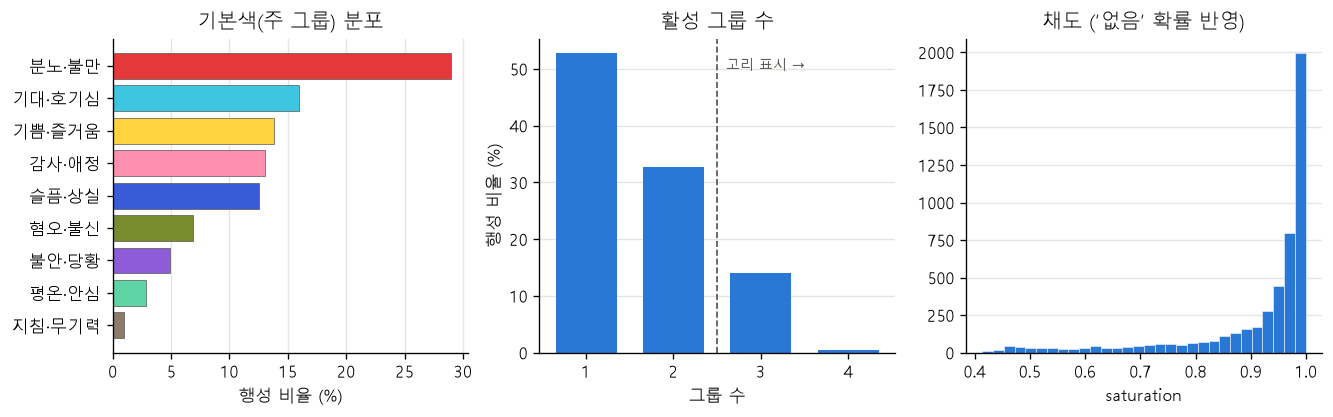

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
vc = pdf["primary"].value_counts()
color_of = {g["name"]: g["color"] for g in MAPPING["groups"]}
axes[0].barh(vc.index[::-1], vc.values[::-1] / len(pdf) * 100, color=[color_of.get(k, "#B8BCC6") for k in vc.index[::-1]],
             edgecolor="#52514e", linewidth=0.4)
axes[0].set_title("기본색(주 그룹) 분포")
axes[0].set_xlabel("행성 비율 (%)")
na = pdf["n_active"].value_counts().sort_index()
axes[1].bar(na.index, na.values / len(pdf) * 100, color=SERIES[0], width=0.7)
axes[1].axvline(MAPPING["params"]["ring_min_active_groups"] - 0.5, color="#52514e", ls="--", lw=1)
axes[1].text(MAPPING["params"]["ring_min_active_groups"] - 0.4, axes[1].get_ylim()[1] * 0.9, "고리 표시 →", fontsize=8.5, color="#52514e")
axes[1].set_title("활성 그룹 수")
axes[1].set_xlabel("그룹 수")
axes[1].set_ylabel("행성 비율 (%)")
axes[2].hist(pdf["saturation"], bins=30, color=SERIES[0], edgecolor="white", linewidth=0.3)
axes[2].set_title("채도 (‘없음’ 확률 반영)")
axes[2].set_xlabel("saturation")
for a in axes:
    a.grid(axis="x" if a is axes[0] else "y", color="#e4e4e0", lw=0.8)
save_fig(fig, FIG / "planet_param_distribution_test.png")
plt.show()

**결과 해석**

- 고리 비율은 test에서 **14.5%**로, 평가자 기준(13.4%)과 비슷하다. validation에서 정한 기준이 test에도 맞는다.
- 기본색은 분노·불만 29%, 기대·호기심 16%, 기쁨·즐거움 14%, 감사·애정 13%, 슬픔·상실 13% 순이다. 평가자 기준 분포(분노·불만 32%, 기대·호기심 18%, 감사·애정 17% …)와 순서가 비슷하다. 댓글 데이터라 분노 비율이 높으며, 일기에서는 달라질 것이다.
- **부끄러움·자책은 기본색으로 한 번도 나오지 않는다**(평가자 기준으로도 0.9%). 지침·무기력도 0.9%뿐이다(평가자 기준 4.6%). 희소 감정이 색으로 드러나기 어렵다.
- 그룹 점수 계산 방식도 비교했다(threshold 대비 점수, logit 차이). 현재 방식(그룹 내 최대 확률)이 주 그룹 일치율이 가장 높아 유지했다.
- 빛 번짐은 p10–p90이 0.09–0.88로, 긍정·부정을 잘 구분한다.
- **크기는 거의 구분되지 않는다**(p10–p90 1.09–1.15). 모델이 대표 감정에 거의 항상 높은 확률을 주기 때문이다. 크기는 감정 강도보다 일기 길이·사진 수 같은 다른 정보로 정하는 방안을 제안한다.
- 채도는 대부분 1에 가깝다. ‘없음’이 높은 담담한 글에서만 낮아진다(p10 0.72).

## 6. 가상 일기 → 행성 미리보기

`ai/configs/demo_diaries.json`의 가상 일기(개발자 작성)를 감정 모델에 넣고, 매핑 결과를 2D로 그린다.

그림 저장: ai/outputs/emotion/baseline_v2021_s42/figures/planet_previews_demo.png | 글꼴 누락 없음


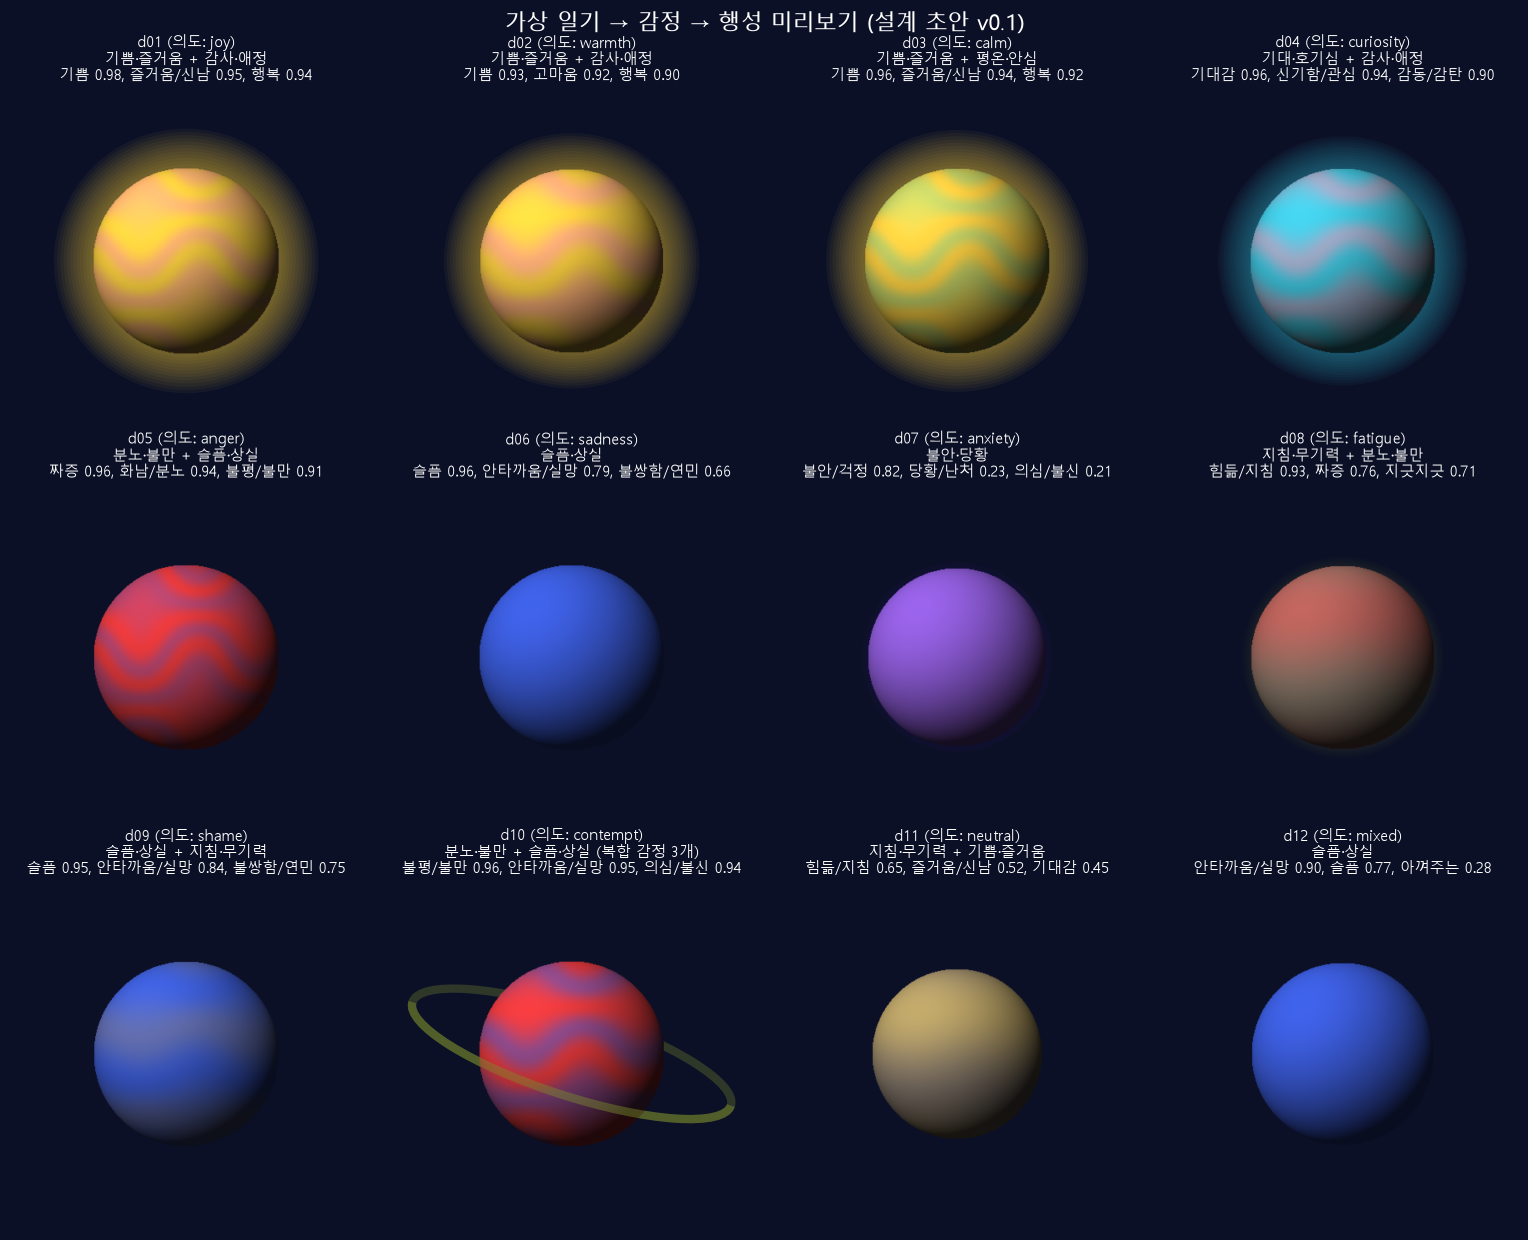

,id,의도,기본색 그룹,보조색 그룹,고리,채도,빛,크기
0,d01,joy,기쁨·즐거움,감사·애정,False,0.993,0.929,1.143
1,d02,warmth,기쁨·즐거움,감사·애정,False,0.991,0.859,1.129
2,d03,calm,기쁨·즐거움,평온·안심,False,0.968,0.911,1.138
3,d04,curiosity,기대·호기심,감사·애정,False,0.977,0.763,1.137
4,d05,anger,분노·불만,슬픔·상실,False,0.994,0.096,1.138
5,d06,sadness,슬픔·상실,-,False,0.992,0.096,1.137
6,d07,anxiety,불안·당황,-,False,0.980,0.165,1.097
7,d08,fatigue,지침·무기력,분노·불만,False,0.965,0.232,1.128
8,d09,shame,슬픔·상실,지침·무기력,False,0.960,0.095,1.136
9,d10,contempt,분노·불만,슬픔·상실,True,0.993,0.112,1.139


In [8]:
from src.emotion.predict import EmotionPredictor

info = json.loads((RUN / "metrics.json").read_text(encoding="utf-8"))
predictor = EmotionPredictor(P.repo_root / info["checkpoint_dir"])
demo = load_json(P.configs / "demo_diaries.json")["diaries"]
demo_probs = predictor.predict_proba([d["text"] for d in demo])
demo_planets = [compute_planet(p, LABELS, MAPPING) for p in demo_probs]

fig, axes = plt.subplots(3, 4, figsize=(13, 10.5), facecolor=SPACE_BG)
for ax, d, pl in zip(axes.ravel(), demo, demo_planets):
    top3 = ", ".join(f"{e['label']} {e['prob']:.2f}" for e in pl["emotions"]["top"][:3])
    render_planet(ax, pl["planet"], title=f"{d['id']} (의도: {d['intended']})\n{pl['summary']}\n{top3}")
fig.suptitle("가상 일기 → 감정 → 행성 미리보기 (설계 초안 v0.1)", color="white", fontsize=13)
fig.tight_layout()
save_fig(fig, FIG / "planet_previews_demo.png")
plt.show()

rows = [{"id": d["id"], "의도": d["intended"], "기본색 그룹": pl["emotions"]["groups"][0]["name"],
         "보조색 그룹": pl["emotions"]["groups"][1]["name"] if pl["planet"]["accent_color"] else "-",
         "고리": pl["planet"]["ring"]["visible"], "채도": pl["planet"]["saturation"], "빛": pl["planet"]["glow"],
         "크기": pl["planet"]["size_scale"]} for d, pl in zip(demo, demo_planets)]
display(pd.DataFrame(rows))
_ = (RUN / "demo_planets.json").write_text(json.dumps(
    [{"id": d["id"], **pl} for d, pl in zip(demo, demo_planets)], ensure_ascii=False, indent=1), encoding="utf-8")

**결과 해석**

- 가상 일기 12개(개발자 작성)의 미리보기다. 기본색이 의도와 맞는 경우는 기쁨, 기대, 분노, 슬픔, 불안, 지침 6개다.
- 고마움(d02)과 편안함(d03)은 기본색이 기쁨이지만, 의도한 감정이 **보조색 띠로** 나타난다.
- 자책(d09)은 모델이 부끄러움·죄책감을 잡지 못해 슬픔 행성이 된다.
- 담담한 일기(d11)는 채도가 0.78로 다른 행성(0.96~0.99)보다 확실히 옅다.
- 고리는 혐오(d10, 분노·슬픔·혐오 3개 그룹)에만 붙는다. 대부분의 일기는 한두 감정 중심이므로, 고리를 드문 표시로 둔 설계 의도와 맞는다.

## 7. 프론트 전달용 출력 형식 (JSON)

일기 1개에 대해 아래 형태의 JSON을 백엔드가 저장하고 프론트(3D)에 전달하는 것을 제안한다.
`planet`은 렌더링 파라미터, `emotions`는 감정 설명 UI(예: “기쁨 0.91, 고마움 0.74”)에 쓸 수 있다.

In [9]:
example = demo_planets[0]
print(json.dumps(example | {"emotions": example["emotions"] | {"groups": example["emotions"]["groups"][:3] + ["..."]}},
                 ensure_ascii=False, indent=1))

{
 "mapping_version": "0.1-draft",
 "emotions": {
  "top": [
   {
    "label": "기쁨",
    "prob": 0.9781
   },
   {
    "label": "즐거움/신남",
    "prob": 0.9526
   },
   {
    "label": "행복",
    "prob": 0.9363
   },
   {
    "label": "감동/감탄",
    "prob": 0.6984
   },
   {
    "label": "고마움",
    "prob": 0.6072
   }
  ],
  "none_prob": 0.011,
  "groups": [
   {
    "id": "joy",
    "name": "기쁨·즐거움",
    "score": 0.9781,
    "top_label": "기쁨",
    "active": true
   },
   {
    "id": "warmth",
    "name": "감사·애정",
    "score": 0.6984,
    "top_label": "감동/감탄",
    "active": false
   },
   {
    "id": "calm",
    "name": "평온·안심",
    "score": 0.4154,
    "top_label": "편안/쾌적",
    "active": false
   },
   "..."
  ]
 },
 "planet": {
  "base_color": "#FED240",
  "accent_color": "#FF8FB1",
  "accent_ratio": 0.417,
  "saturation": 0.993,
  "glow": 0.929,
  "turbulence": 0.7,
  "band_count": 4,
  "ring": {
   "visible": false,
   "color": null,
   "opacity": 0.0
  },
  "size_scale": 1.143,
  "valenc

## 8. 결론과 협의 필요 사항

**완료한 것**
- 44개 감정 → 10개 감정 그룹 + ‘없음’ 매핑. 데이터 군집으로 근거를 확인했고, 모든 라벨이 정확히 한 번 배정되는지 코드로 검증한다.
- 행성 파라미터 8종(기본색, 보조색·비율, 띠, 소용돌이, 빛, 채도, 고리, 크기) 계산 함수와 프론트 전달용 JSON 형식
- 실제 모델 출력(test 5,000건)에 적용해 분포를 점검했다. 고리 기준은 validation에서 평가자 기준에 맞춰 보정했다(test 14.5% vs 기준 13.4%).
- 가상 일기 → 감정 → 행성 2D 미리보기

**협의가 필요한 것**
1. 그룹 색 팔레트와 그룹 구성(특히 안타까움/실망 → 슬픔 배정)
2. **크기 결정 방식**: 감정 강도로는 구분되지 않으므로, 일기 길이·사진 수 등으로 정할지
3. 희소 감정(부끄러움·자책, 지침·무기력)이 색으로 드러나지 않는 문제: 모델 개선으로 풀지, 매핑에서 보정할지
4. 프론트(3D)에서 파라미터를 어떻게 표현할지: 띠·소용돌이·고리의 실제 렌더링 방식
5. 실제 일기(동의받은 소량)로 사용자 체감 평가